#### Natalia Cercos 

# Image Formation in a Telescope

Modern astrophysics is built upon observations, thus it is of great interest to understand how
optical systems work and how they influence the formation of an image in the telescope focus.
Every telescope is characterized by a set of optical elements. Refracting telescopes have lenses,
while reflecting telescopes have a set of mirrors. Each optical element, due to its imperfections,
introduces certain perturbation to the image of the observed object.
The appearance of the object image in the telescope's focus is described with the so-called
Point Spread Function (PSF). The PSF describes the system's response to a point source. In its
base it represents the diffraction pattern of a point source in the telescope's focus. Every optical
system, based on its set of optical elements, will have a unique PSF. Figure 1 shows an example
of the PSF in the system’s focus.

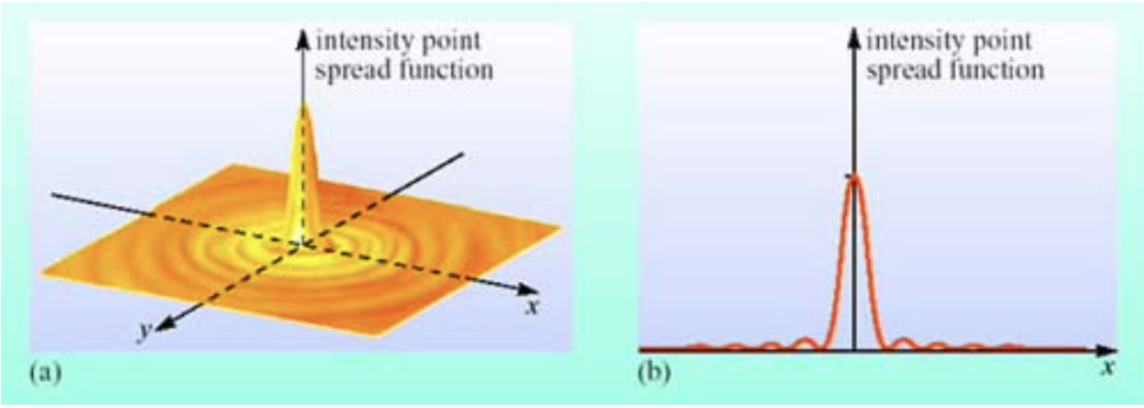

In [2]:
from IPython.display import Image, display
display(Image(filename="Photos1/H2-1.png", width=600))

**Figure 1:** Example PSF of an optical system: (a) 2D distribution of the PSF on the screen (b)
cross-section of this distribution along the x-axis of the screen.


In this exercise, the aim is to explore how the PSF of an optical system is constructed and to
examine its influence on the image formation in the system's focus. Since the telescope aperture
is in most cases circular, we will focus on the ciruclar aperture. However modern, very large
telescopes are segmented. These segments are hexagonal, and because of this, the telescope
aperture is essentially hexagonal.

### Point Spread Function – PSF

The PSF is essentially a diffraction image (distribution of radiation intensity) of the source
projected in the focus of the optical system. In case of astronomical sources, which are are very
distant point sources, the PSF is as a result of the Fraunhofer diffraction on the telescope
apreture. According to Maxwell's electromagnetic theory, light is an electromagnetic wave,
representing oscillations of electric and magnetic fields in space and time. The intensity of light
is defined as the square of the intensity of the electric field. If we know the shape of the electric
field vector at a given point in space, we can easily calculate the radiation intensity at that point,
i.e., we can determine the PSF of the optical system.


Let’s consider a telescope of a circular aperture and calculate the electric field vector at a
specific point behind the aperture. Let’s divide the aperture into small elements (smaller than
the wavelength of the observed light, see Figure 2). From each of these small elements of the
aperture, we can assume that a spherical wave arrives at point P (based on the Huygens-Fresnel
principle). The total electric field vector will be the superposition of the electric field vectors
of each of these waves (i.e. summing over the elements of the telescope's aperture). The
assumption that the aperture segments are smaller than the wavelength guarantees that all
waves will be in the same phase at point P. The value of the electric field at point P will depend
on the position of the wave source (x, y) (the position of the surface element SdS) and the
position of point P. The mathematical operation of superposing these waves at point P is
actually a Fourier transformation of the wavefront at the aperture. This operation converts the
shape of the wavefront at the aperture into its image on the detector located in the focus.

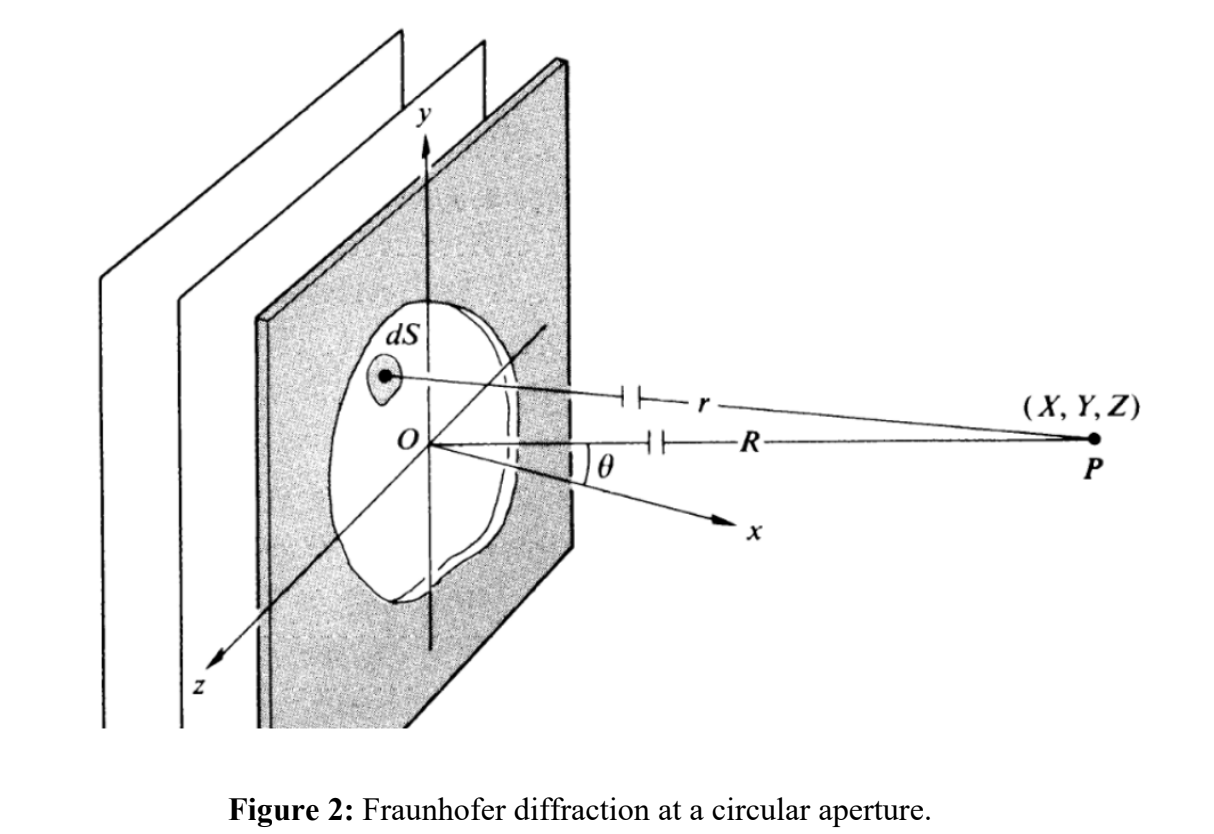

In [3]:
from IPython.display import Image, display
display(Image(filename="Photos1/h2-2.png", width=600))

Since we assumed that a flat wave is arriving at the aperture, the wave will have the same phase
at every point of the aperture, i.e., it will have a constant amplitude and phase. This holds only
if there are no deformations to the wavefront (thiss will be discussed this in more detail later).
From the previous explanation, we can conclude that the wavefront takes the shape of the
telescope aperture (e.g., circular aperture), and from this, we get that the PSF is the square of
the Fourier transform of the telescope aperture A:

$$PSF = |F(A(x,y))|^2$$

Depending on the shape of the aperture, we will have different PSF patterns. In the case of an
ideal system, a flate wave and a circular aperture, the PSF in the focus has the shape of an Airy
function.

### Task 1: 
Calculate the PSF for a circular aperture. Assume that the telescope has a circular
aperture with a radius of 128, 64, and 32, within the field of 256×256 size.



We calculate the PSF for circular apertures with radii of 128, 64, and 32 pixels on a 256 × 256 grid:


$$PSF = |F(A(x,y))|^2$$


The aperture function is 1 inside the circle and 0 outside.

In [28]:
import numpy as np
import matplotlib.pyplot as plt

N = 256
radii = [128, 64, 32] # 0,1,2

y, x = np.indices((N, N))
xc = yc = N // 2

We first construct the aperture with radius 128 pixels, centred on the grid.

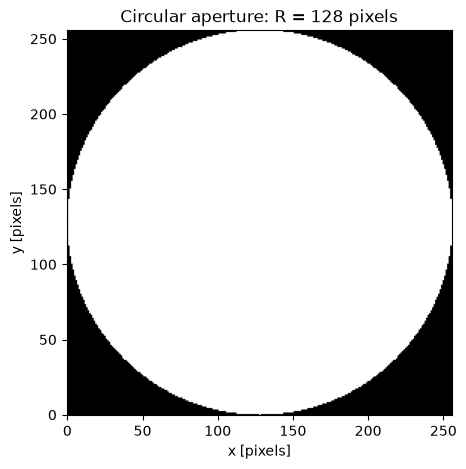

In [29]:
R = radii[0]

aperture = ((x - xc)**2 + (y - yc)**2 <= R**2).astype(float)

plt.figure(figsize=(5, 5))
plt.imshow(aperture, cmap="gray", origin="lower")
plt.title(f"Circular aperture: R = {R} pixels")
plt.xlabel("x [pixels]")
plt.ylabel("y [pixels]")
plt.show()

Now to calculate the PSF, we must perform a 2D Fourier transfrom on the aperture. It needs to be normalized. 

In [30]:
# Fourier transform 
amplitude = np.fft.fft2(aperture)

# Centre the diffraction pattern
amplitude = np.fft.fftshift(amplitude)

# Squared modulus gives the intensity
psf = np.abs(amplitude)**2

# Normalise the peak to 1
psf = psf / psf.max()

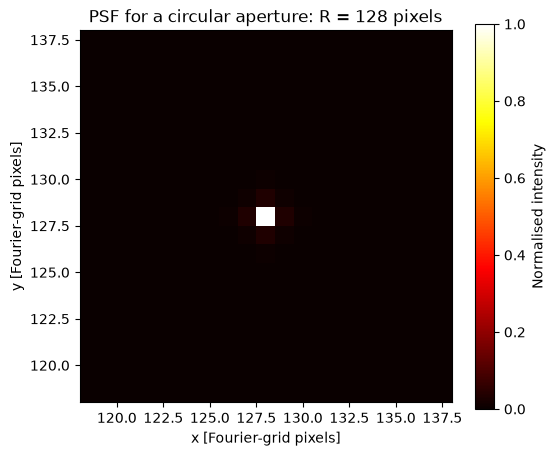

In [31]:
from matplotlib.colors import LogNorm


plt.figure(figsize=(6, 5))

plt.imshow(
    psf,
    cmap="hot",
    origin="lower",
    vmin=0,
    vmax=1
)

plt.xlim(xc - 10, xc + 10)
plt.ylim(yc - 10, yc + 10) ## Its a zoom 

plt.title(f"PSF for a circular aperture: R = {R} pixels")
plt.xlabel("x [Fourier-grid pixels]")
plt.ylabel("y [Fourier-grid pixels]")
plt.colorbar(label="Normalised intensity")

plt.show()

**Note: We start with a circular aperture of radius 128 pixels. To get its PSF, we take the 2D Fourier transform and square its absolute value. We then move the peak to the centre and divide by its maximum so the peak equals 1.

We zoom in and use a logarithmic colour scale to see the faint structure around the bright centre. It looks pixelated because the peak covers very few pixels.

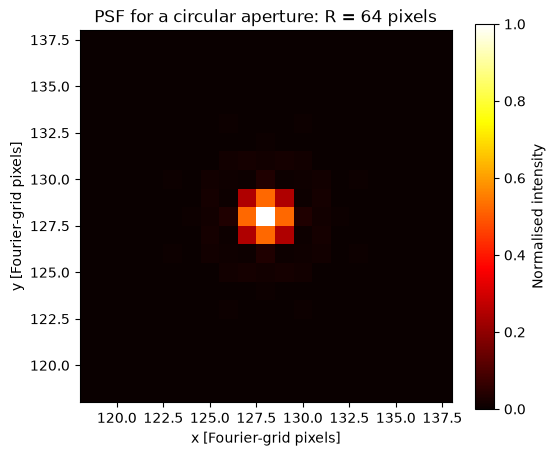

In [32]:
R = 64

# Create the smaller aperture
aperture = ((x - xc)**2 + (y - yc)**2 <= R**2).astype(float)

# Calculate and normalise its PSF
amplitude = np.fft.fftshift(np.fft.fft2(aperture))
psf = np.abs(amplitude)**2
psf /= psf.max()

# Use the same scale and zoom as before
plt.figure(figsize=(6, 5))
plt.imshow(
    psf,
    cmap="hot",
    origin="lower",
    vmin=0,
    vmax=1
)
plt.xlim(xc - 10, xc + 10)
plt.ylim(yc - 10, yc + 10)
plt.title(f"PSF for a circular aperture: R = {R} pixels")
plt.xlabel("x [Fourier-grid pixels]")
plt.ylabel("y [Fourier-grid pixels]")
plt.colorbar(label="Normalised intensity")
plt.show()

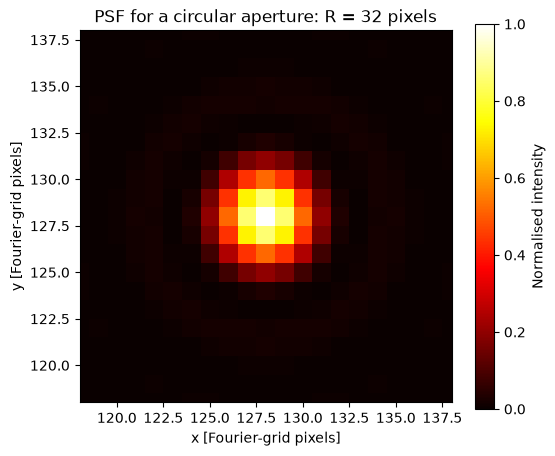

In [33]:
R = 32

aperture = ((x - xc)**2 + (y - yc)**2 <= R**2).astype(float)

amplitude = np.fft.fftshift(np.fft.fft2(aperture))
psf = np.abs(amplitude)**2
psf /= psf.max()

plt.figure(figsize=(6, 5))
plt.imshow(
    psf,
    cmap="hot",
    origin="lower",
    vmin=0,
    vmax=1
)
plt.xlim(xc - 10, xc + 10)
plt.ylim(yc - 10, yc + 10)
plt.title(f"PSF for a circular aperture: R = {R} pixels")
plt.xlabel("x [Fourier-grid pixels]")
plt.ylabel("y [Fourier-grid pixels]")
plt.colorbar(label="Normalised intensity")
plt.show()

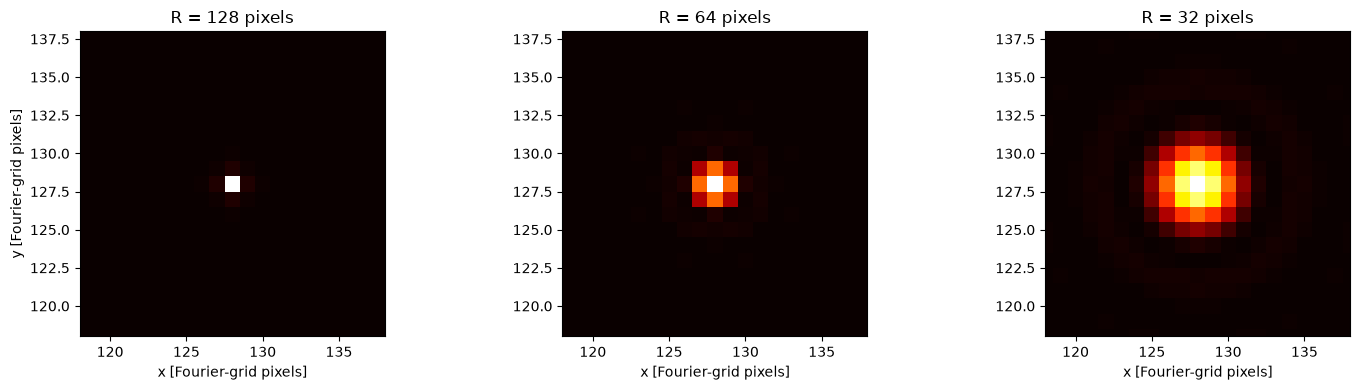

In [34]:
# See all the plots 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, R in zip(axes, [128, 64, 32]):

    # Create the aperture
    aperture = ((x - xc)**2 + (y - yc)**2 <= R**2).astype(float)

    # Calculate and normalise the PSF
    amplitude = np.fft.fftshift(np.fft.fft2(aperture))
    psf = np.abs(amplitude)**2
    psf /= psf.max()

    # Plot each PSF with the same settings
    ax.imshow(psf, cmap="hot", origin="lower", vmin=0, vmax=1)
    ax.set_xlim(xc - 10, xc + 10)
    ax.set_ylim(yc - 10, yc + 10)
    ax.set_title(f"R = {R} pixels")
    ax.set_xlabel("x [Fourier-grid pixels]")

axes[0].set_ylabel("y [Fourier-grid pixels]")

plt.tight_layout()
plt.show()

### Task 1a: 
Explore how the PSF would appear in the case of other telescope mirror shapes (e.g. square, hexagonal).

### Square aperture

We use a square with side length $L = 64$ pixels. Points inside it satisfy:

$$
-\frac{L}{2} \leq x-x_c < \frac{L}{2}
\quad \text{and} \quad
-\frac{L}{2} \leq y-y_c < \frac{L}{2}.
$$

The aperture is 1 inside the square and 0 outside.

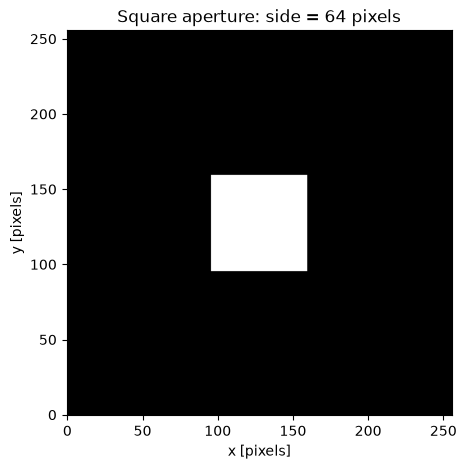

In [35]:
side = 64

# Square aperture centred on the grid
square_aperture = (
    (x - xc >= -side / 2) & (x - xc < side / 2) &
    (y - yc >= -side / 2) & (y - yc < side / 2)
).astype(float)

plt.figure(figsize=(5, 5))
plt.imshow(square_aperture, cmap="gray", origin="lower", vmin=0, vmax=1)
plt.title(f"Square aperture: side = {side} pixels")
plt.xlabel("x [pixels]")
plt.ylabel("y [pixels]")
plt.show()

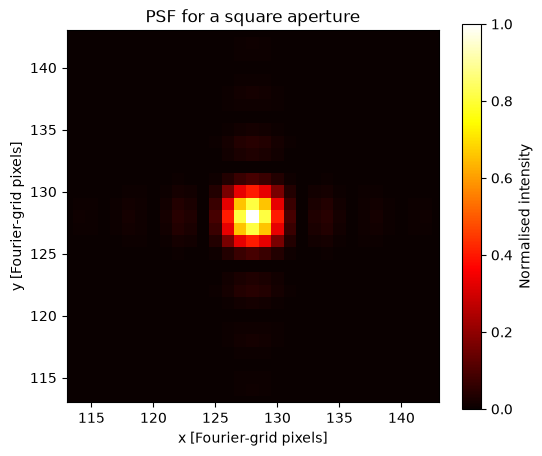

In [36]:
# Calculate the PSF of the square aperture
amplitude = np.fft.fftshift(np.fft.fft2(square_aperture))
square_psf = np.abs(amplitude)**2
square_psf /= square_psf.max()

# Plot the PSF
plt.figure(figsize=(6, 5))
plt.imshow(square_psf, cmap="hot", origin="lower", vmin=0, vmax=1)

plt.xlim(xc - 15, xc + 15)
plt.ylim(yc - 15, yc + 15)

plt.title("PSF for a square aperture")
plt.xlabel("x [Fourier-grid pixels]")
plt.ylabel("y [Fourier-grid pixels]")
plt.colorbar(label="Normalised intensity")
plt.show()

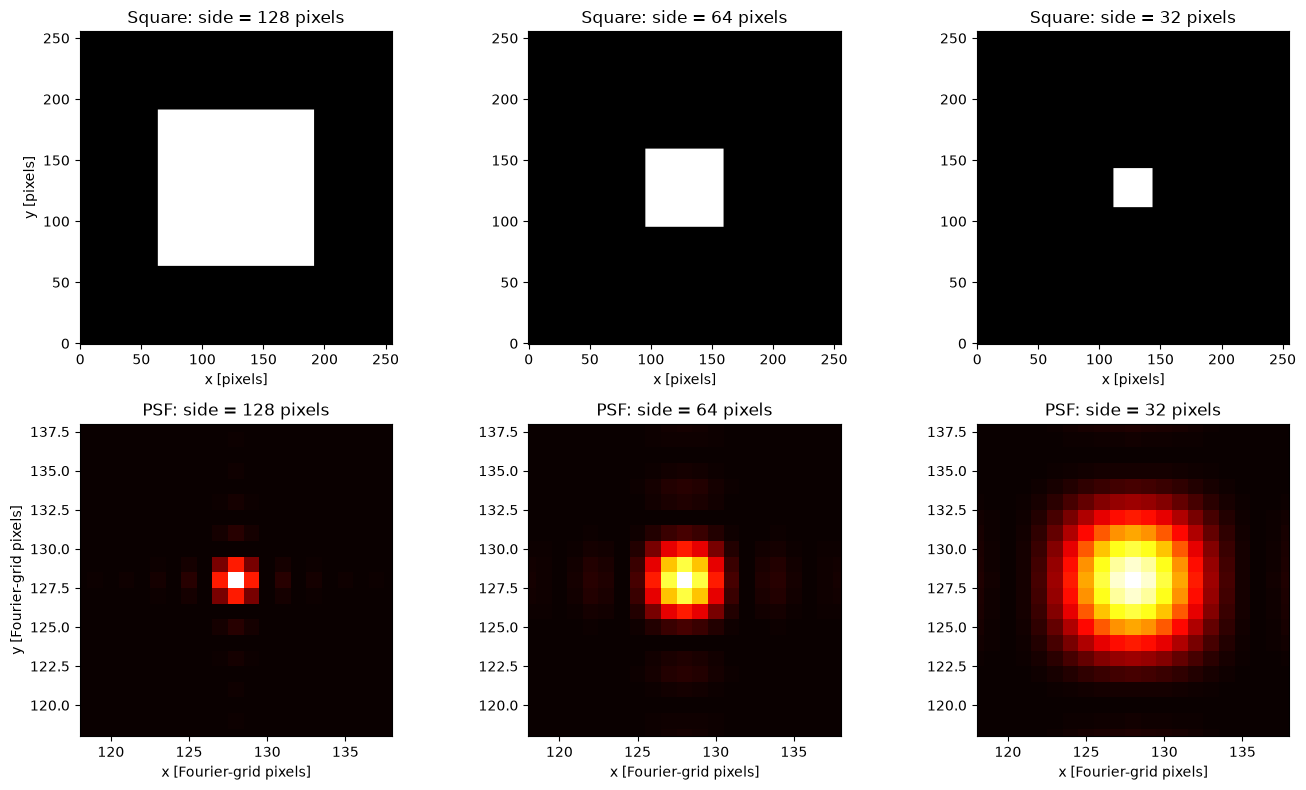

In [37]:
# Compare square apertures and their PSFs
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for col, side in enumerate([128, 64, 32]):

    # Create the square aperture
    square_aperture = (
        (x - xc >= -side / 2) & (x - xc < side / 2) &
        (y - yc >= -side / 2) & (y - yc < side / 2)
    ).astype(float)

    # Calculate and normalise its PSF
    amplitude = np.fft.fftshift(np.fft.fft2(square_aperture))
    square_psf = np.abs(amplitude)**2
    square_psf /= square_psf.max()

    # Aperture
    axes[0, col].imshow(
        square_aperture, cmap="gray", origin="lower",
        vmin=0, vmax=1)
    axes[0, col].set_title(f"Square: side = {side} pixels")

    # PSF
    axes[1, col].imshow(
        square_psf, cmap="hot", origin="lower",
        vmin=0, vmax=1)
    axes[1, col].set_xlim(xc - 10, xc + 10)
    axes[1, col].set_ylim(yc - 10, yc + 10)
    axes[1, col].set_title(f"PSF: side = {side} pixels")

axes[0, 0].set_ylabel("y [pixels]")
axes[1, 0].set_ylabel("y [Fourier-grid pixels]")

for ax in axes[0]:
    ax.set_xlabel("x [pixels]")

for ax in axes[1]:
    ax.set_xlabel("x [Fourier-grid pixels]")

plt.tight_layout()
plt.show()

### Hexagonal aperture

We now try a regular hexagon, where $R$ is the distance from its
centre to a vertex. Using centred coordinates $X=x-x_c$ and $Y=y-y_c$,
points inside satisfy:

$$
|Y| \leq \frac{\sqrt{3}}{2}R
\quad \text{and} \quad
\sqrt{3}|X| + |Y| \leq \sqrt{3}R.
$$

The aperture is 1 inside the hexagon and 0 outside.

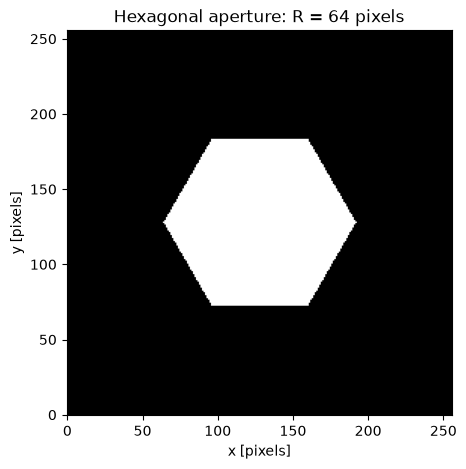

In [39]:
R = 64

# Coordinates relative to the centre
X = x - xc
Y = y - yc

# Regular hexagonal aperture
hex_aperture = (
    (np.abs(Y) <= np.sqrt(3) * R / 2) &
    (np.sqrt(3) * np.abs(X) + np.abs(Y) <= np.sqrt(3) * R)
).astype(float)

plt.figure(figsize=(5, 5))
plt.imshow(hex_aperture, cmap="gray", origin="lower", vmin=0, vmax=1)
plt.title(f"Hexagonal aperture: R = {R} pixels")
plt.xlabel("x [pixels]")
plt.ylabel("y [pixels]")
plt.show()

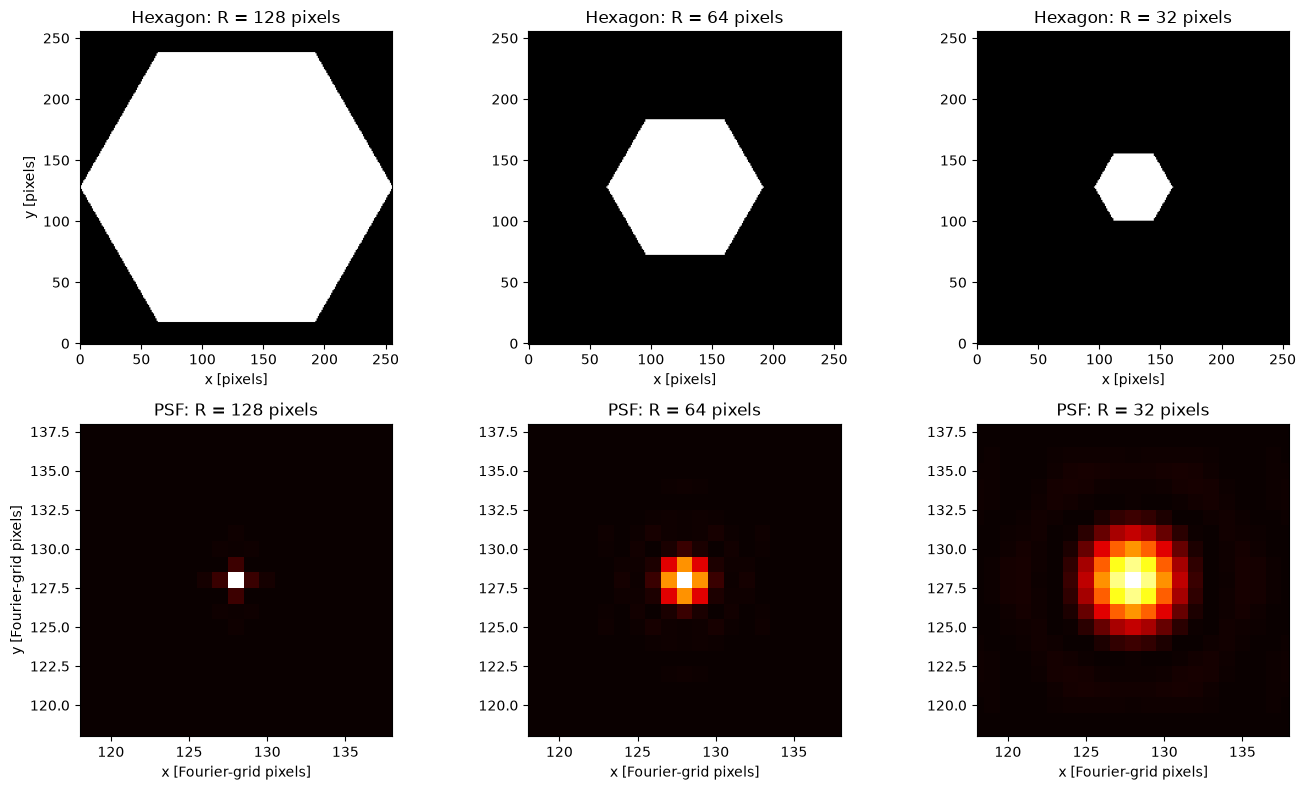

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for col, R in enumerate([128, 64, 32]):

    # Create the hexagonal aperture
    hex_aperture = (
        (np.abs(Y) <= np.sqrt(3) * R / 2) &
        (np.sqrt(3) * np.abs(X) + np.abs(Y) <= np.sqrt(3) * R)
    ).astype(float)

    # Calculate and normalise its PSF
    amplitude = np.fft.fftshift(np.fft.fft2(hex_aperture))
    hex_psf = np.abs(amplitude)**2
    hex_psf /= hex_psf.max()

    # Top row: aperture
    axes[0, col].imshow(
        hex_aperture, cmap="gray", origin="lower",
        vmin=0, vmax=1)
    axes[0, col].set_title(f"Hexagon: R = {R} pixels")

    # Bottom row: PSF
    axes[1, col].imshow(
        hex_psf, cmap="hot", origin="lower",
        vmin=0, vmax=1)
    axes[1, col].set_xlim(xc - 10, xc + 10)
    axes[1, col].set_ylim(yc - 10, yc + 10)
    axes[1, col].set_title(f"PSF: R = {R} pixels")

axes[0, 0].set_ylabel("y [pixels]")
axes[1, 0].set_ylabel("y [Fourier-grid pixels]")

for ax in axes[0]:
    ax.set_xlabel("x [pixels]")

for ax in axes[1]:
    ax.set_xlabel("x [Fourier-grid pixels]")

plt.tight_layout()
plt.show()

## Image Formation 

Let’s now consider how the the source image is forming, especially in case of extended sources.
Since the radiation detectors have discrete sampling systems, we can assume that the object is
composed of many point sources of radiation, each of which forms an image as a PSF.
According to the superposition principle, the resulting image is the sum of the PSF values at
given detector points for each individual source. This mathematical operation is essentially a
convolution of the object and the telescope's PSF (see Figure 3). In this case, the PSF should
be considered as a weighting function, meaning it must be normalized, and for that reason, we
can also refer to it as a sort of distribution.

Thus, the image we will see in the telescope’s focus depends on the PSF of our telescope, i.e.,
on the telescope's aperture and its size.

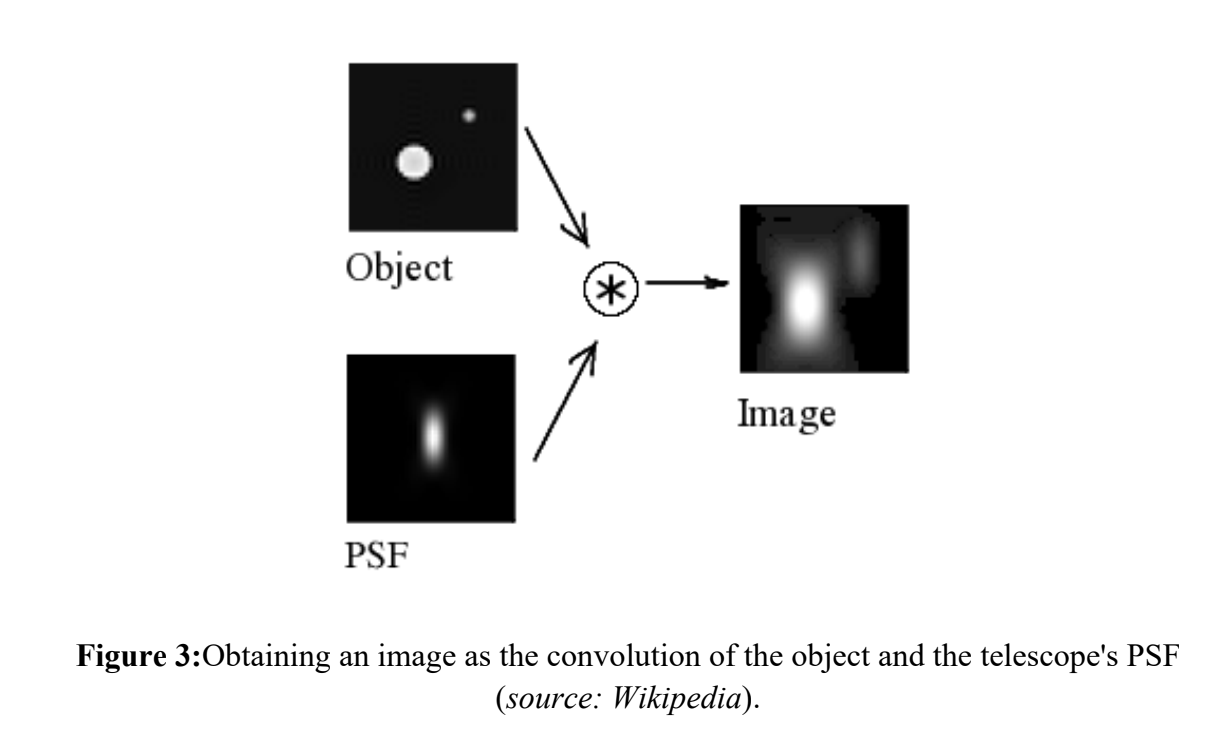

In [43]:
from IPython.display import Image, display
display(Image(filename="Photos1/ImageForm.png", width=600))

### Task 2: 
Produce the image of any ideal source (e.g. model of an ideal star or galaxy) seen
through the circular aperture (e.g. one of those created within the previous task).

We model an ideal source and convolve it with a circular-aperture PSF:

$$
\mathrm{Image} = \mathrm{Source} * \mathrm{PSF}.
$$

Here, $*$ represents convolution. We start with a single point source.

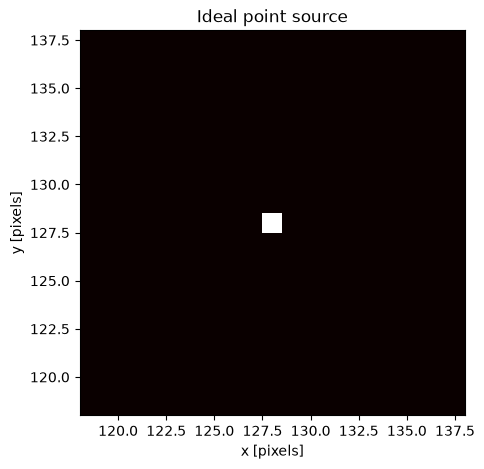

In [44]:
# Ideal point source at the centre
source = np.zeros((N, N))
source[yc, xc] = 1

plt.figure(figsize=(5, 5))
plt.imshow(source, cmap="hot", origin="lower", vmin=0, vmax=1)
plt.xlim(xc - 10, xc + 10)
plt.ylim(yc - 10, yc + 10)
plt.title("Ideal point source")
plt.xlabel("x [pixels]")
plt.ylabel("y [pixels]")
plt.show()

In [45]:
R = 32

# Circular aperture
circular_aperture = (
    (x - xc)**2 + (y - yc)**2 <= R**2
).astype(float)

# Calculate the PSF
amplitude = np.fft.fftshift(np.fft.fft2(circular_aperture))
circular_psf = np.abs(amplitude)**2

# Normalise its total intensity to 1
circular_psf /= circular_psf.sum()

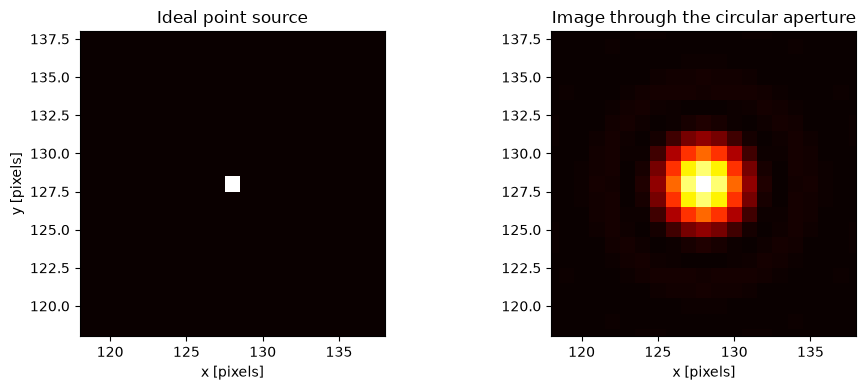

In [46]:
from scipy.signal import convolve2d

# Convolve the source with the PSF
full_image = convolve2d(source, circular_psf, mode="full")

# Keep a 256 × 256 image, preserving our centre convention
image = full_image[yc:yc + N, xc:xc + N]

# Compare the ideal source and the resulting image
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(source, cmap="hot", origin="lower")
axes[0].set_title("Ideal point source")

axes[1].imshow(image, cmap="hot", origin="lower")
axes[1].set_title("Image through the circular aperture")

for ax in axes:
    ax.set_xlim(xc - 10, xc + 10)
    ax.set_ylim(yc - 10, yc + 10)
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

Our source starts as a single bright pixel. After applying the telescope's
PSF, its light spreads over several pixels because of diffraction.

We now model an extended source as a small, uniformly bright disk
with a radius of 5 pixels.

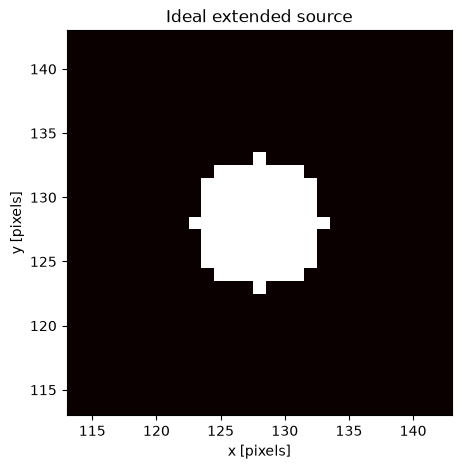

In [47]:
source_radius = 5

# Small disk of uniform brightness
extended_source = (
    (x - xc)**2 + (y - yc)**2 <= source_radius**2
).astype(float)

plt.figure(figsize=(5, 5))
plt.imshow(extended_source, cmap="hot", origin="lower")
plt.xlim(xc - 15, xc + 15)
plt.ylim(yc - 15, yc + 15)
plt.title("Ideal extended source")
plt.xlabel("x [pixels]")
plt.ylabel("y [pixels]")
plt.show()

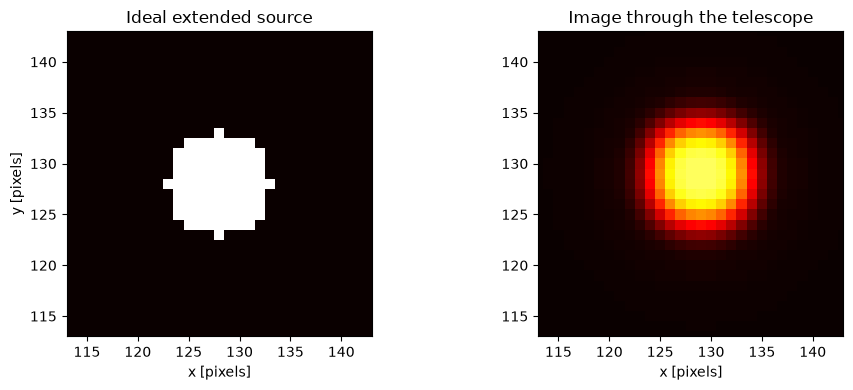

In [49]:
# Apply the PSF to the extended source
extended_image = convolve2d(
    extended_source, circular_psf, mode="same")

# Compare the source and its image
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(extended_source, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[0].set_title("Ideal extended source")

axes[1].imshow(extended_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Image through the telescope")

for ax in axes:
    ax.set_xlim(xc - 15, xc + 15)
    ax.set_ylim(yc - 15, yc + 15)
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

## Wavefront Perturbations and Zernike Polynomials

So far, we have only considered a flat wavefront passing through an ideal optical system.
However, this is not what happens in reality. The wavefront is first affected by the atmosphere
(turbulence), and then by the imperfections of the optical elements, which lead to aberrations,
coma, astigmatism, defocusing, and other effects. Since these changes only affect the phase of
the wave, their impact on the PSF is reflected in the following way:

$$
PSF = \left|\mathcal{F}\left(A(x,y)e^{i\Phi(x,y)}\right)\right|^2,
$$

where $\Phi(x,y)$ is the function that describes phase changes of the wavefront at the point (x,y) of
the telescope aperture. This phase change functions can be represented by Zernike polynomials,
which are defined on a circular aperture of radius 1 and are orthogonal to each other:

$$
Z_n^m(\rho,\phi)
=
\sqrt{\frac{2(n+1)}{1+\delta_{0,m}}}
\cdot R_n^m(\rho)\cdot
\begin{cases}
\cos(m\phi), & m \geq 0\\
\sin(m\phi)\cdot(-1), & m < 0
\end{cases}
$$

where n and m represent the order of the Zernike polynomial (radial and azimuthal,
respectively), and $\rho$ and $\phi$ are usual cylindrical coordinates. From their definition, it can be
seen that in Zernike polynomials, the radial and azimuthal parts of the polynomial are
separated. The first term in the polynomial is a normalization factor, derived from the
normalization condition of the polynomial:

$$
\int_0^{2\pi}\int_0^1
\left[Z_n^m(\rho,\phi)\right]^2
\rho\,d\rho\,d\phi = \pi.
$$

Different causes of wavefront perturbations are described by different Zernike polynomials.
These polynomials are obtained from the series expansion of the wavefront on a circular
aperture, where in the zeroth order we have $Z_0^0(\rho,\phi)=1$. Examples of polynomials for some
of the wavefront perturbations due to different abberations are given in Table 1. The function
$\Phi$ in the main equation represents the linear combination of the polynomials corresponding to
all present wavefront perturbations. The visualization of different polynomials and their
combinations can be examine at https://webs.optics.arizona.edu/gsmith/Zernike.html and
https://wp.optics.arizona.edu/jcwyant/miscellaneous/neat-graphics/zernike-polynomials/.

### Task 3: 

Examin how defocusing of the optical system will affect the resulting image. Compare
the obtained image with the image for a focused system.

For defocusing, we use the Zernike polynomial:

$$
Z_2^0(\rho,\phi)=\sqrt{3}(2\rho^2-1),
$$

where $\rho=r/R$, with $r$ the distance from the aperture centre
and $R$ the aperture radius.

The phase is:

$$
\Phi = a\,Z_2^0,
$$

where $a$ controls the strength of defocusing. We include this phase
in the PSF calculation:

$$
PSF =
\left|\mathcal{F}\left(A(x,y)e^{i\Phi(x,y)}\right)\right|^2.
$$

In [50]:
R = 32

# Distance from the aperture centre
r = np.sqrt((x - xc)**2 + (y - yc)**2)

# Normalised radial coordinate rho
rho = r / R

# aperture
circular_aperture = (rho <= 1).astype(float)

# Zernike polynomial for defocusing
Z_defocus = np.sqrt(3) * (2 * rho**2 - 1)

In [51]:
a = 1

# Phase change due to defocusing
phase = a * Z_defocus

# Apply the phase to the circular aperture
defocused_aperture = circular_aperture * np.exp(1j * phase)

# Calculate the defocused PSF
amplitude = np.fft.fftshift(np.fft.fft2(defocused_aperture))
defocused_psf = np.abs(amplitude)**2

# Normalise
defocused_psf /= defocused_psf.sum()

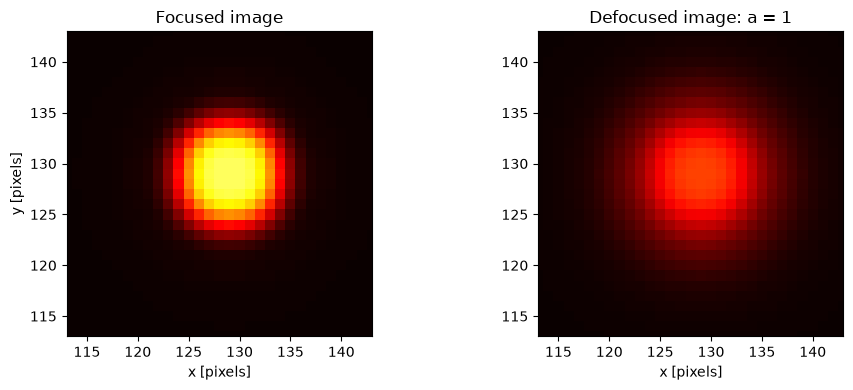

In [52]:
# Image with the focused PSF and defocus
focused_image = convolve2d(
    extended_source, circular_psf, mode="same")

defocused_image = convolve2d(
    extended_source, defocused_psf, mode="same")

# Compare both images
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(
    focused_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[0].set_title("Focused image")

axes[1].imshow(
    defocused_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[1].set_title(f"Defocused image: a = {a}")

for ax in axes:
    ax.set_xlim(xc - 15, xc + 15)
    ax.set_ylim(yc - 15, yc + 15)
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

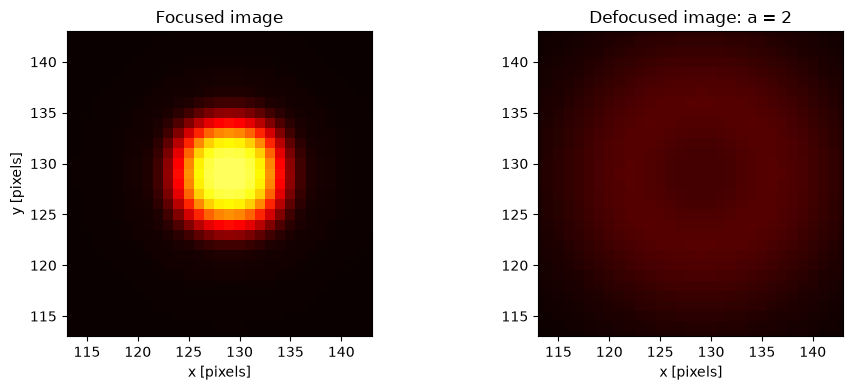

In [55]:
a = 2

# Phase change due to defocusing
phase = a * Z_defocus

# Apply the phase to the circular aperture
defocused_aperture = circular_aperture * np.exp(1j * phase)

# Calculate the defocused PSF
amplitude = np.fft.fftshift(np.fft.fft2(defocused_aperture))
defocused_psf = np.abs(amplitude)**2

# Normalise for convolution
defocused_psf /= defocused_psf.sum()

# Image with the focused PSF
focused_image = convolve2d(
    extended_source, circular_psf, mode="same")

# Image with the defocused PSF
defocused_image = convolve2d(
    extended_source, defocused_psf, mode="same")

# Compare both images with the same colour scale
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(
    focused_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[0].set_title("Focused image")

axes[1].imshow(
    defocused_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[1].set_title(f"Defocused image: a = {a}")

for ax in axes:
    ax.set_xlim(xc - 15, xc + 15)
    ax.set_ylim(yc - 15, yc + 15)
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

Defocusing changes the PSF and spreads the light over a larger region.
The disk becomes less clearly compared with the focused image.
Increasing the defocusing coefficient makes this effect stronger.

### Task 4: 
Consider other influences of wavefront deformation (spherical abberation, coma) on
image formation. Try to create a linear combination and see how it affects the image.

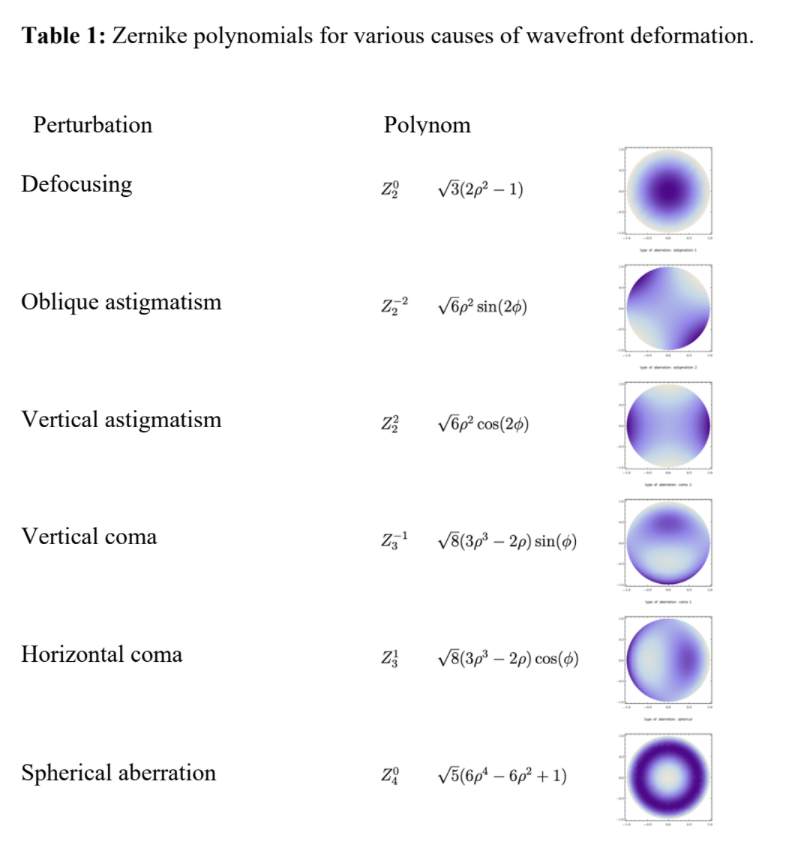

In [56]:
from IPython.display import Image, display
display(Image(filename="Photos1/perturbation.png", width=600))

#### Spherical Aberration

We first try spherical aberration, using the Zernike polynomial:

$$
Z_4^0(\rho)=\sqrt{5}(6\rho^4-6\rho^2+1).
$$

The phase becomes:

$$
\Phi = b\,Z_4^0,
$$

where $b$ controls the strength of spherical aberration.

In [59]:
# Zernike polynomial for spherical aberration
Z_spherical = np.sqrt(5) * (6 * rho**4 - 6 * rho**2 + 1)

# Strength of spherical aberration
b = 1

phase_spherical = b * Z_spherical
spherical_aperture = circular_aperture * np.exp(1j * phase_spherical)

# Calculate and normalise
amplitude = np.fft.fftshift(np.fft.fft2(spherical_aperture))
spherical_psf = np.abs(amplitude)**2
spherical_psf /= spherical_psf.sum()

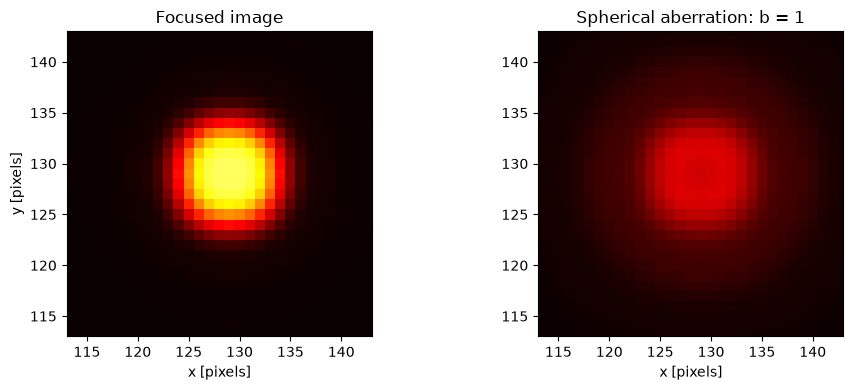

In [60]:
# Image with spherical aberration
spherical_image = convolve2d(
    extended_source, spherical_psf, mode="same")

# Compare with the focused image
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(
    focused_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[0].set_title("Focused image")

axes[1].imshow(
    spherical_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[1].set_title(f"Spherical aberration: b = {b}")

for ax in axes:
    ax.set_xlim(xc - 15, xc + 15)
    ax.set_ylim(yc - 15, yc + 15)
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

#### Coma

We now try horizontal coma, using the Zernike polynomial:

$$
Z_3^1(\rho,\phi)=\sqrt{8}(3\rho^3-2\rho)\cos\phi.
$$

The phase is:

$$
\Phi=c\,Z_3^1,
$$

where $c$ controls the strength of coma.

In [61]:
# Angle measured from the horizontal axis
phi = np.arctan2(y - yc, x - xc)

# Zernike polynomial for horizontal coma
Z_coma = np.sqrt(8) * (3 * rho**3 - 2 * rho) * np.cos(phi)

In [62]:
# Strength of coma
c = 1

# Apply the phase to the aperture
phase_coma = c * Z_coma
coma_aperture = circular_aperture * np.exp(1j * phase_coma)

# Calculate and normalise the PSF
amplitude = np.fft.fftshift(np.fft.fft2(coma_aperture))
coma_psf = np.abs(amplitude)**2
coma_psf /= coma_psf.sum()

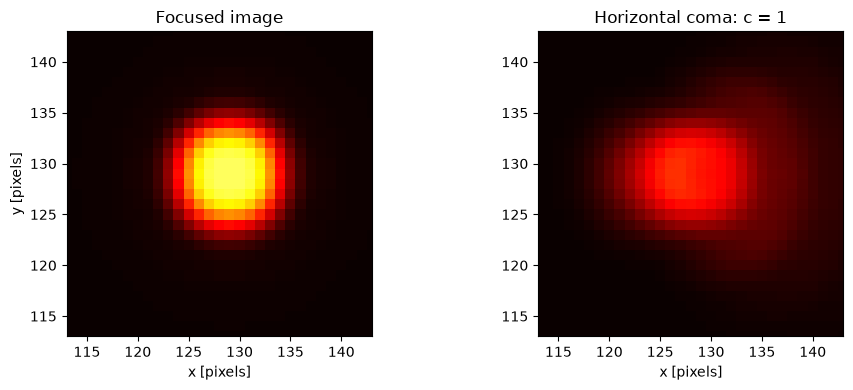

In [63]:
# Image with coma
coma_image = convolve2d(
    extended_source, coma_psf, mode="same"
)

# Compare both images
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(
    focused_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[0].set_title("Focused image")

axes[1].imshow(
    coma_image, cmap="hot", origin="lower", vmin=0, vmax=1)
axes[1].set_title(f"Horizontal coma: c = {c}")

for ax in axes:
    ax.set_xlim(xc - 15, xc + 15)
    ax.set_ylim(yc - 15, yc + 15)
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

#### Combining spherical aberration and coma

We combine both effects by adding their phase contributions:

$$
\Phi = b\,Z_4^0 + c\,Z_3^1.
$$

In [65]:
b = 1
c = 1

combined_phase = b * Z_spherical + c * Z_coma

# Apply the combined phase to the aperture
combined_aperture = circular_aperture * np.exp(1j * combined_phase)

# Calculate and normalise the PSF
amplitude = np.fft.fftshift(np.fft.fft2(combined_aperture))
combined_psf = np.abs(amplitude)**2
combined_psf /= combined_psf.sum()

# Apply the PSF to the disk
combined_image = convolve2d(
    extended_source, combined_psf, mode="same")

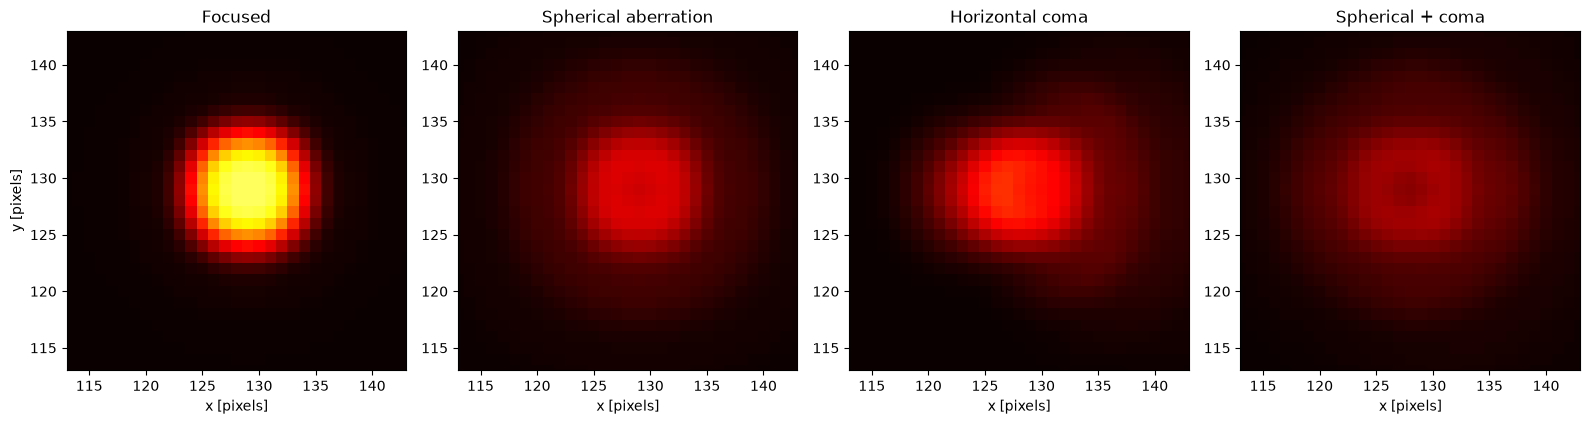

In [66]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

images = [
    focused_image,
    spherical_image,
    coma_image,
    combined_image
]

titles = [
    "Focused",
    "Spherical aberration",
    "Horizontal coma",
    "Spherical + coma"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="hot", origin="lower", vmin=0, vmax=1)
    ax.set_xlim(xc - 15, xc + 15)
    ax.set_ylim(yc - 15, yc + 15)
    ax.set_title(title)
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

### Task 5: 
Reflectors have a secondary mirror, which effectively reduces the aperture area.
Compare the PSF and final image in the case of a telescope with a circular aperture (of your
choice, on the same grid as in the first task) and with a central obstruction of 0.1 and 0.5 radii
of the telescope's primary mirror.

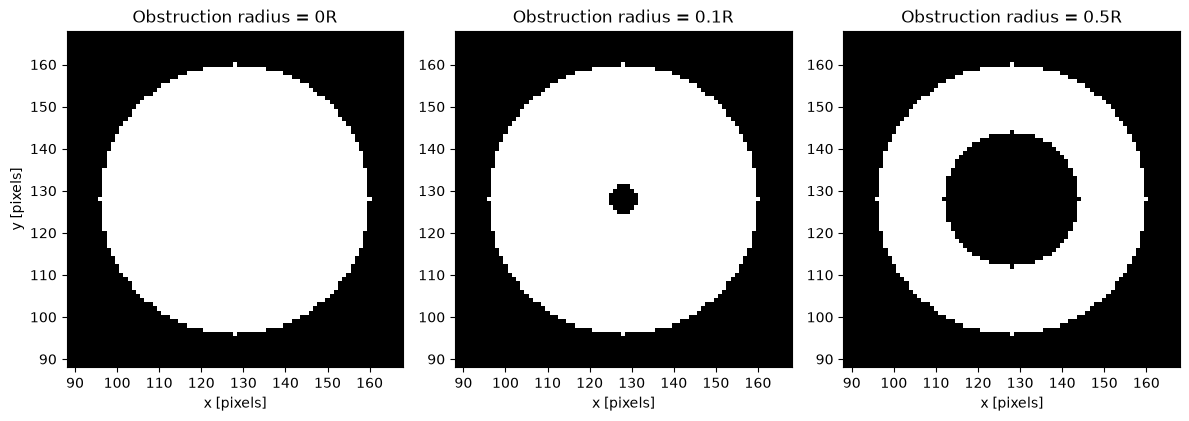

In [67]:
R = 32
r = np.sqrt((x - xc)**2 + (y - yc)**2)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, obstruction in zip(axes, [0, 0.1, 0.5]):

    obstruction_radius = obstruction * R

    if obstruction == 0:
        aperture = (r <= R).astype(float)
    else:
        aperture = (
            (r <= R) & (r > obstruction_radius)
        ).astype(float)

    ax.imshow(aperture, cmap="gray", origin="lower", vmin=0, vmax=1)
    ax.set_xlim(xc - 40, xc + 40)
    ax.set_ylim(yc - 40, yc + 40)
    ax.set_title(f"Obstruction radius = {obstruction}R")
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

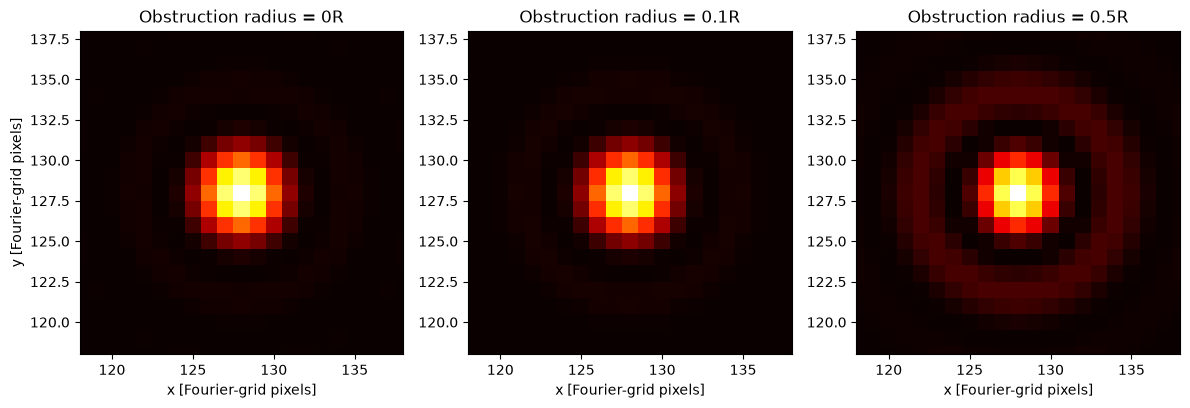

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, obstruction in zip(axes, [0, 0.1, 0.5]):

    obstruction_radius = obstruction * R

    # Create the aperture
    if obstruction == 0:
        aperture = (r <= R).astype(float)
    else:
        aperture = (
            (r <= R) & (r > obstruction_radius)
        ).astype(float)

    # Calculate and normalise the PSF
    amplitude = np.fft.fftshift(np.fft.fft2(aperture))
    psf = np.abs(amplitude)**2
    psf /= psf.sum()

    # Divide by the peak only for display
    ax.imshow(
        psf / psf.max(),
        cmap="hot",
        origin="lower",
        vmin=0,
        vmax=1
    )
    ax.set_xlim(xc - 10, xc + 10)
    ax.set_ylim(yc - 10, yc + 10)
    ax.set_title(f"Obstruction radius = {obstruction}R")
    ax.set_xlabel("x [Fourier-grid pixels]")

axes[0].set_ylabel("y [Fourier-grid pixels]")

plt.tight_layout()
plt.show()

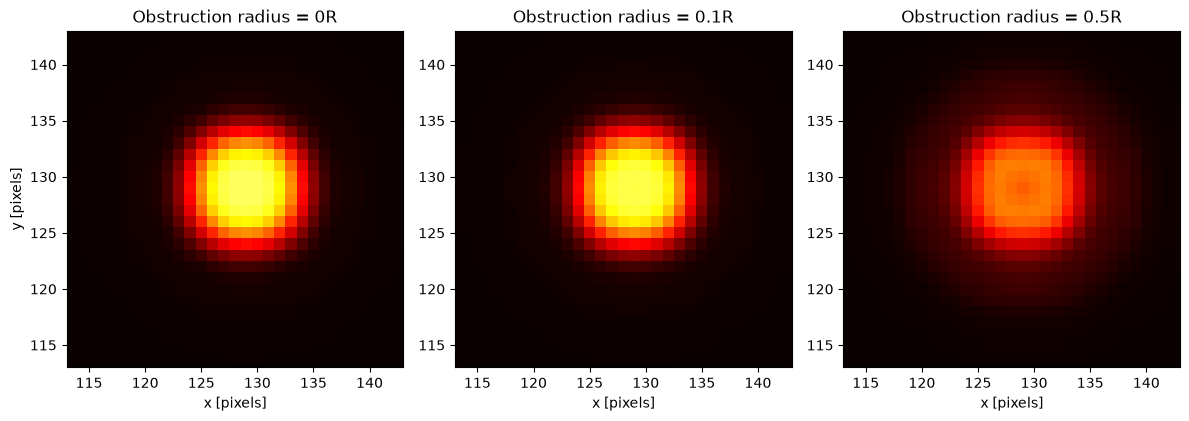

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, obstruction in zip(axes, [0, 0.1, 0.5]):

    obstruction_radius = obstruction * R

    # Create the aperture
    if obstruction == 0:
        aperture = (r <= R).astype(float)
    else:
        aperture = (
            (r <= R) & (r > obstruction_radius)
        ).astype(float)

    # Calculate and normalise the PSF
    amplitude = np.fft.fftshift(np.fft.fft2(aperture))
    psf = np.abs(amplitude)**2
    psf /= psf.sum()

    # Form the image of the disk
    image = convolve2d(extended_source, psf, mode="same")

    ax.imshow(
        image, cmap="hot", origin="lower", vmin=0, vmax=1
    )
    ax.set_xlim(xc - 15, xc + 15)
    ax.set_ylim(yc - 15, yc + 15)
    ax.set_title(f"Obstruction radius = {obstruction}R")
    ax.set_xlabel("x [pixels]")

axes[0].set_ylabel("y [pixels]")

plt.tight_layout()
plt.show()

# Notes

The aim of this homework was to understand how a telescope changes the appearance of an object. Even a perfectly focused telescope does not show a point source as a perfect point: diffraction spreads its light. The **PSF describes that spread**.

**Task 1 — Circular apertures:** We created circles with radii of 128, 64, and 32 pixels on a 256 × 256 grid. The aperture was 1 where light could pass and 0 outside. We calculated each PSF by taking the 2D Fourier transform and squaring its absolute value. Smaller apertures gave wider peaks; larger apertures gave narrower peaks and better resolution.

**Task 1a — Other shapes:** We repeated the calculation for squares and hexagons. Changing the aperture shape changed the diffraction pattern: circular apertures give rings, squares give structure along two perpendicular directions, and hexagons give sixfold symmetry. The faint parts were difficult to see on our linear colour scale.

**Task 2 — Forming an image:** We created a source consisting of one bright pixel, then a small bright disk. We applied the circular PSF using convolution. This means that each point in the source spreads its light according to the PSF, and all those contributions are added together. The point became a small spot, and the disk developed softer edges.

**Task 3 — Defocusing:** We kept the same aperture and disk but changed the wavefront phase using a Zernike polynomial for defocus. We calculated a new PSF and applied it to the disk. This let us compare focused and defocused images without changing the object.

**Task 4 — Other aberrations:** We tried spherical aberration and horizontal coma using their Zernike polynomials. Spherical aberration redistributed the light while keeping an approximately circular image. Coma introduced asymmetry. We then added their phases before calculating the PSF to simulate both effects acting together.
